# Strong scaling — rbc_nob, z-slab vs 3-D 분할 (MPM-STD, KISTI-6 GH200, PaScaL_TDMA)

| 항목 | 값 |
|---|---|
| 문제 | NOB 글리세롤 Rayleigh–Bénard (Ra 1e6, Pr 2547, ΔT 40 K, γ_z 2.6, viscous_coupling_number 12) — cv12 본런 덱과 같은 물리 |
| 코드 | `apps/rbc_nob_scalability` — rbc_nob 시간 루프와 같은 호출, 구간 타이머 (잡마다 rbc_nob 과 모니터 줄 비교 게이트 통과) |
| 분할 | **slab** = z 만 (1 × 1 × np) — 분산 TDMA 는 z 하나.  **pencil** = 3 방향 고르게 (2×1×1, 2×2×1, 2×2×2) — x·y·z 분산 TDMA + 압력 xy-평면 전치 |
| 배치 | np 2·4 = **노드당 1 랭크** (노드 안 통신 회피).  np 8 은 8 노드 × 1 (그림)과 2 노드 × 4 (6 절 표) 둘 다 쟀다.  x 축 괄호 = 노드 × 노드당 랭크 |
| 시간 | 냉시작 200 스텝 중 앞 50 제외 150 스텝. 구간마다 ms/step **랭크 max**, 반복 2 회 중 step_total 대표 런 (`summarize.py` 와 같은 계산) |
| 격자 | 전역 **256³** 와 **512³** 고정, 6 × 6 × 1 박스 |
| 지표 | 기준 = 각 (격자, 분할) 의 np 1.  speedup S = T(1) / T(np),  efficiency E = S / np |
| 데이터 | jobs 1197086 (slab np 1–8), 1197168 (pencil np 1–8, np 8 = 2×4), rbc_penB (np 8 = 8×1).  그림은 `plot/figures/` 에 png 로도 저장 |

In [1]:
# 로그인 노드는 프로세스당 가상메모리 제한 — OpenBLAS 가 코어 수만큼 스레드 버퍼를 잡다 커널이 죽는다.
# numpy 를 부르기 전에 1 스레드로 묶는다.
import os
for _v in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")

import pathlib, sys
HERE = pathlib.Path.cwd()
if not (HERE / "scaling_plot.py").exists():
    HERE = pathlib.Path("/scratch/t639a05/MPM-STD_C/apps/rbc_nob_scalability/plot")
sys.path.insert(0, str(HERE))
import scaling_plot as sp

MODE = "strong"
SIZES = [256, 512]
RESULTS = {   # 결과 폴더 (여러 개면 합친다). pencil_internode 에는 np 8 (8×1) 의 slab 런도 있다.
    "slab":   ["results/strong_internode", "results/pencil_internode"],
    "pencil": ["results/pencil_internode"],
}
LABELS = {"slab": "z-slab  (1×1×np)", "pencil": "3-D  (2×1×1, 2×2×1, 2×2×2)"}
study = lambda n, k: "%s_%d_%s" % (MODE, n, k)
data = {}
for n in SIZES:
    for k in RESULTS:
        try:
            data[study(n, k)] = sp.metrics(sp.collect(RESULTS[k], study(n, k)), MODE)
        except FileNotFoundError as err:   # 아직 안 잰 조합은 건너뛴다
            print("skip:", err)
sp.table(data)

def pair(n):
    """격자 n 의 slab vs pencil — 색은 분할 방식 (slab = 1 번, pencil = 2 번, 모든 그림에서 같다)."""
    keys = [k for k in RESULTS if study(n, k) in data]
    return {study(n, k): data[study(n, k)] for k in keys}, {study(n, k): LABELS[k] for k in keys}

skip: no runs for strong_256_pencil under ['/scratch/t639a05/MPM-STD_C/apps/rbc_nob_scalability/results/pencil_internode']
skip: no runs for strong_512_pencil under ['/scratch/t639a05/MPM-STD_C/apps/rbc_nob_scalability/results/pencil_internode']
study                      np  place   decomp    ms/step  speedup    eff   TDMA MPI     halo runs spread%
---------------------------------------------------------------------------------------------------------
strong_256_slab             1    1x1    1x1x1     22.215     1.00  1.000      0.000    0.357    2     0.3
strong_256_slab             2    2x1    1x1x2     15.693     1.42  0.708      0.475    0.636    2     0.6
strong_256_slab             4    4x1    1x1x4     11.518     1.93  0.482      0.857    0.686    2     0.8
strong_256_slab             8    2x4    1x1x8      9.477     2.34  0.293      0.763    0.642    2     1.8
strong_512_slab             1    1x1    1x1x1    158.689     1.00  1.000      0.000    0.707    2     0.2
strong_512_s

## 1. Wall-clock time per step

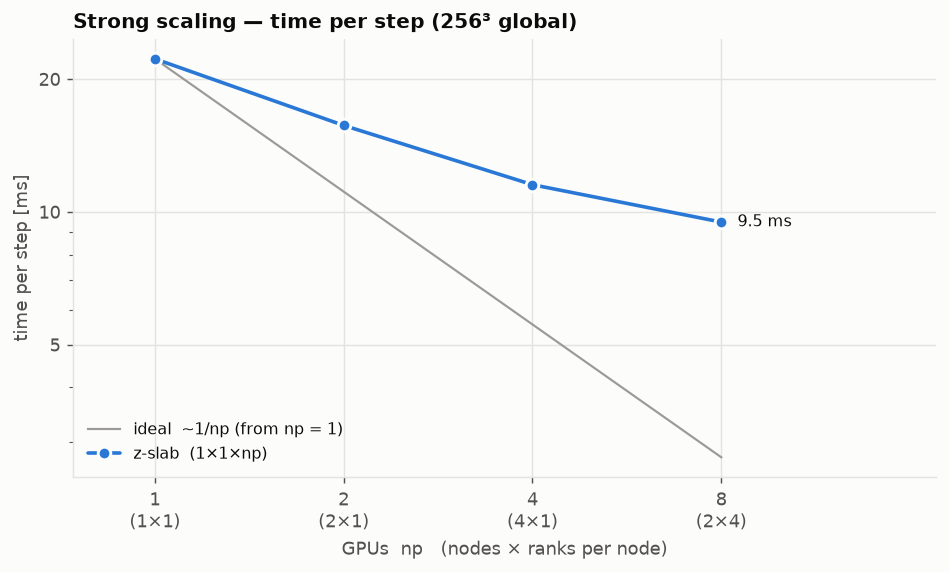

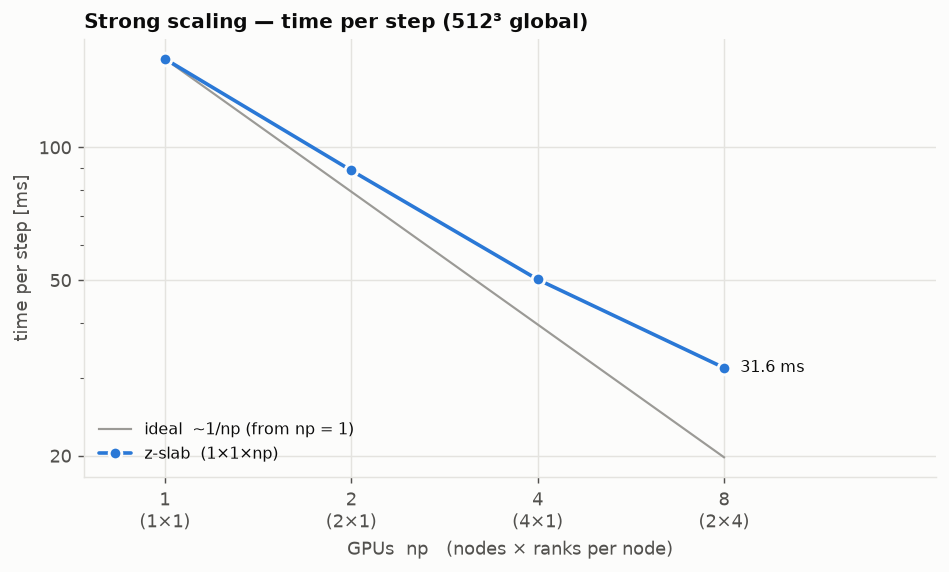

In [2]:
for n in SIZES:
    ds, lab = pair(n)
    sp.line_chart(ds, "total", title="Strong scaling — time per step (%d³ global)" % n,
                  ylabel="time per step [ms]", logy=True, labels=lab,
                  ideal=lambda x, d: d[min(d)]["total"] * min(d) / x, ideal_label="ideal  ~1/np (from np = 1)",
                  fmt="%.1f ms", legend_loc="lower left", fname="strong_time_%d" % n);

## 2. Speedup

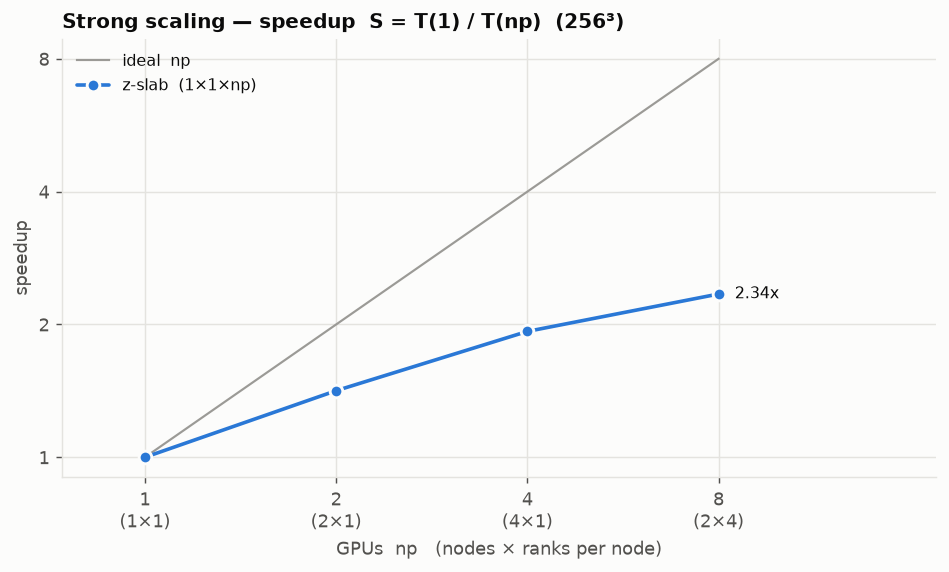

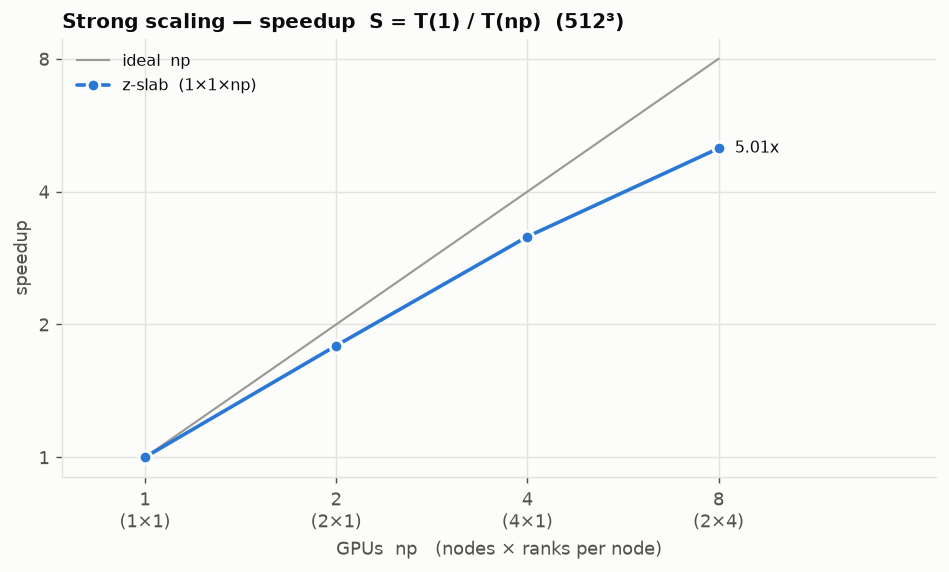

In [3]:
for n in SIZES:
    ds, lab = pair(n)
    sp.line_chart(ds, "speedup", title="Strong scaling — speedup  S = T(1) / T(np)  (%d³)" % n,
                  ylabel="speedup", logy=True, log_base=2, labels=lab, ideal=lambda x, d: x / min(d),
                  ideal_label="ideal  np", fmt="%.2fx", legend_loc="upper left", fname="strong_speedup_%d" % n);

## 3. Parallel efficiency

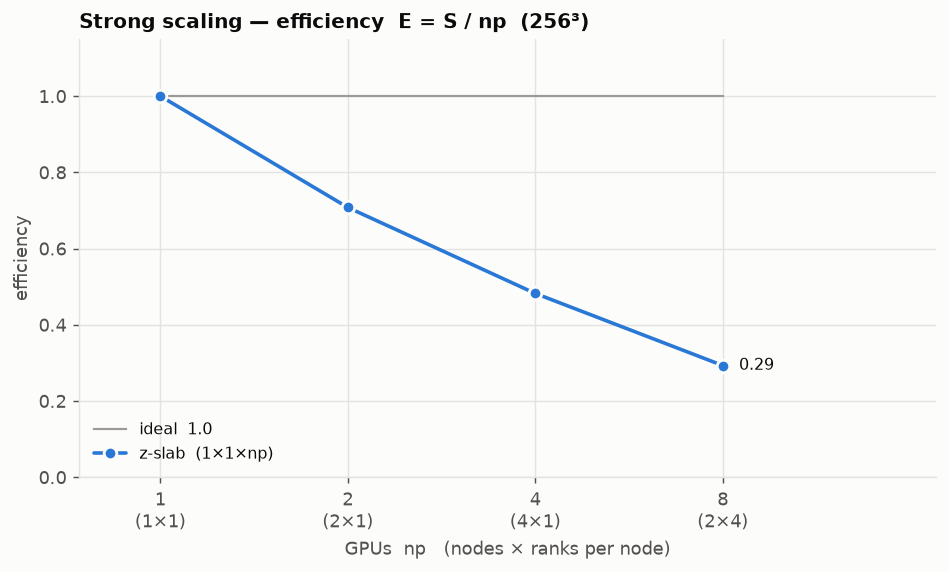

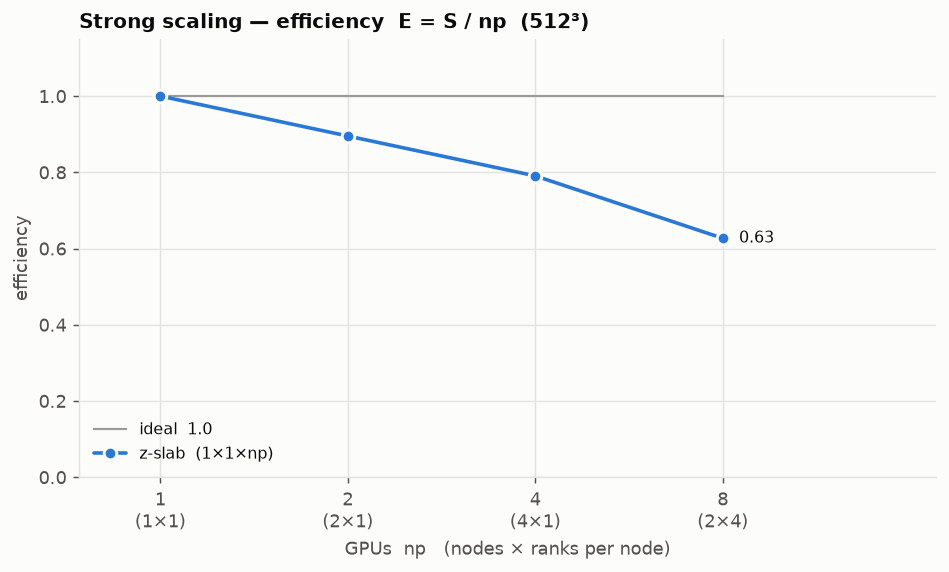

In [4]:
for n in SIZES:
    ds, lab = pair(n)
    sp.line_chart(ds, "eff", title="Strong scaling — efficiency  E = S / np  (%d³)" % n,
                  ylabel="efficiency", logy=False, labels=lab, ideal=lambda x, d: 1.0, ideal_label="ideal  1.0",
                  ylim=(0, 1.15), fmt="%.2f", legend_loc="lower left", fname="strong_efficiency_%d" % n);

## 4. 구간 분해 — 한 스텝이 어디에 쓰이는가

- 누적 막대 = 구간 묶음별 ms/step (랭크 max), 막대 위 숫자 = step_total. 아래에서부터 momentum_solve · scalar_solve ·
  pressure_solve · momentum_rhs · pressure_rhs · halo sync (sync_T + sync_UVW_1 + sync_UVW_2) · other (dt_cfl, dt_viscous,
  properties_1·2, pressure_correct, predictor, clip, monitor).
- scalar 는 RHS 를 따로 부르지 않는다 — 첫 x 스윕 조립에 융합돼 scalar_solve 안에 있다 (`[timing] solver_phases = true` 면 `scalar.build_x`).
- 분산 TDMA 의 MPI 시간은 세 풀이 구간 **안에** 들어 있다 (5 절). pencil 의 압력 xy 전치(Alltoallv)도 pressure_solve 안이다.

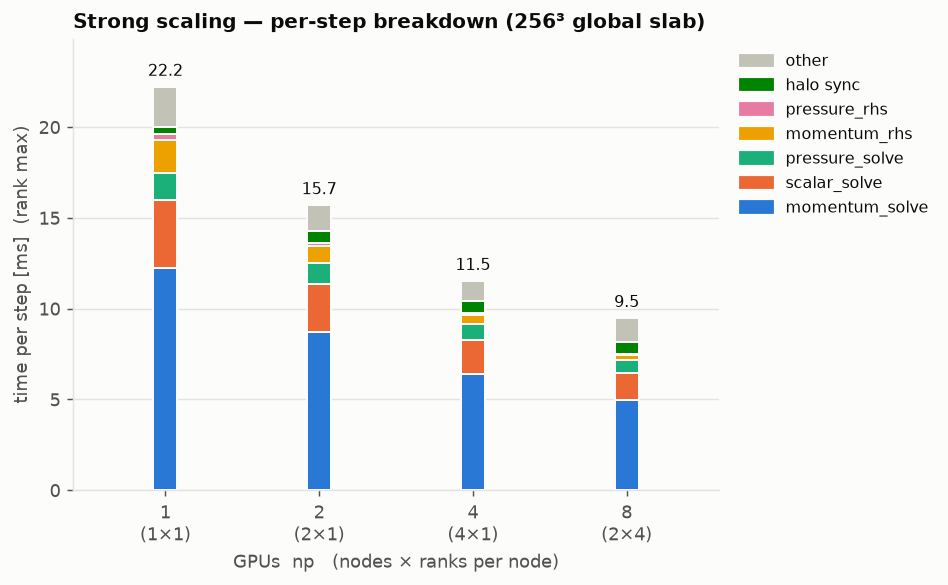

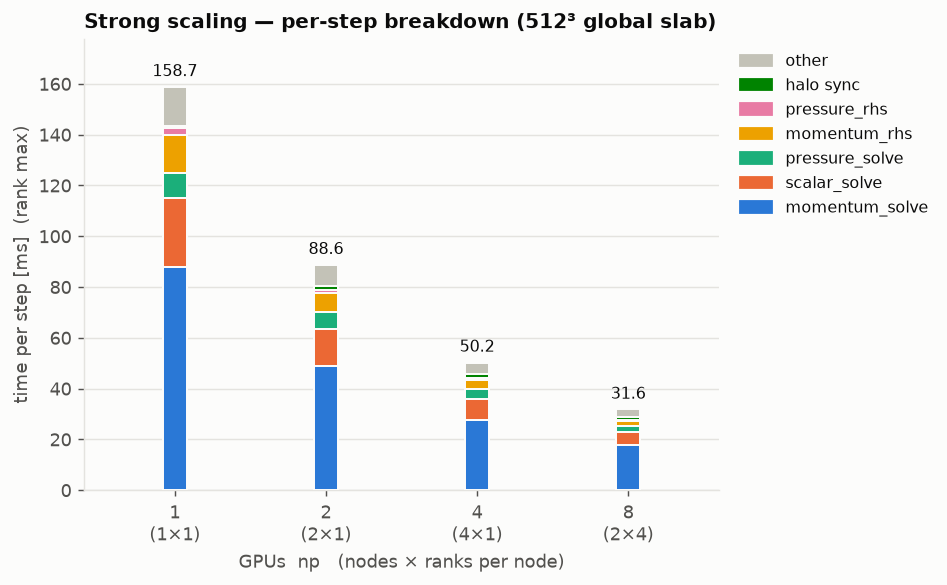

In [5]:
for s, d in data.items():
    sp.phase_chart(d, title="Strong scaling — per-step breakdown (%s)" % sp.label_of(s), fname="strong_phases_%s" % s);

## 5. 통신 시간

- 왼쪽: 분산 TDMA 의 `MPI_Alltoallv` 시간 (`tdma_comm_*` = scalar·momentum 의 x·y·z + pressure 의 z, PaScaL 플랜의
  comm_seconds 훅 — 측정 동기화 없음). **pencil 압력의 xy-평면 전치는 여기에 없다** (훅이 없어 pressure_solve 에만 들어 있다).
- 오른쪽: halo 교환 구간 (`sync_*`: MPI_Sendrecv + 벽 ghost 커널).

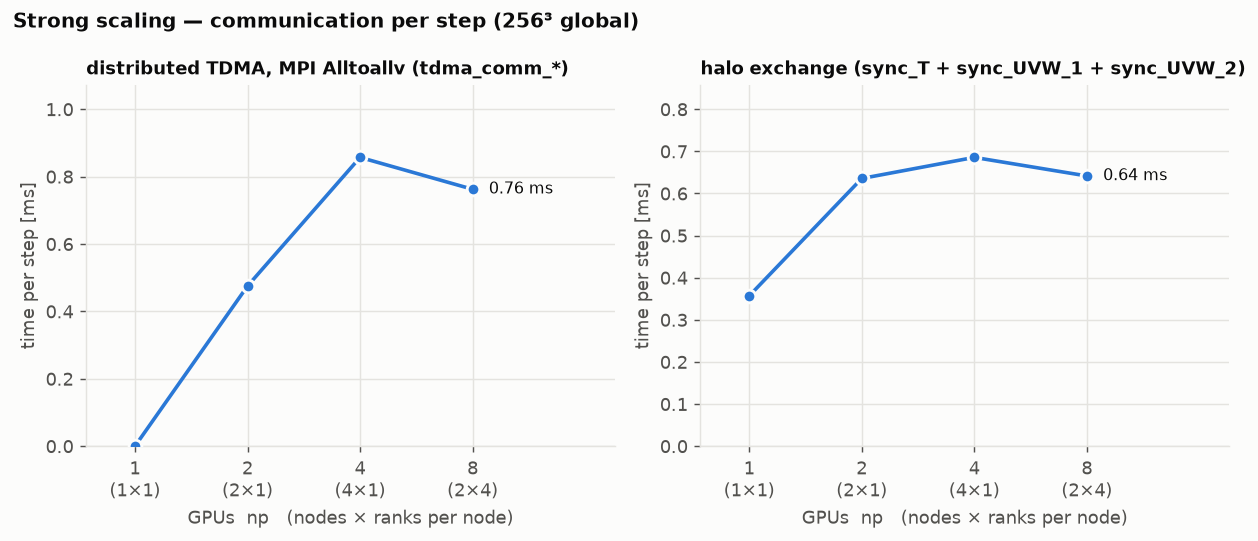

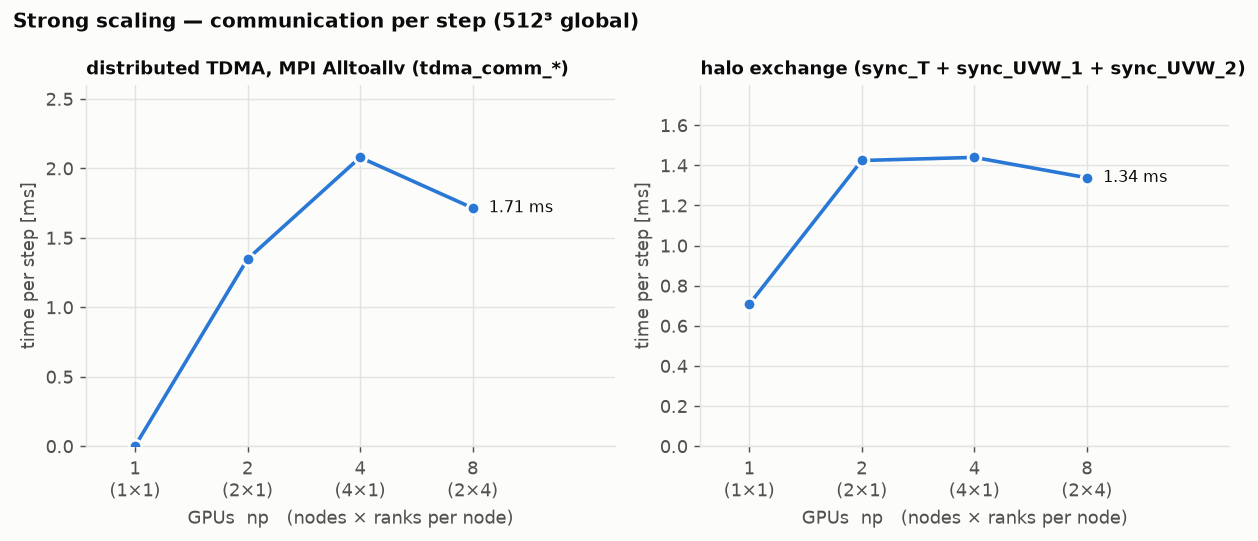

In [6]:
for n in SIZES:
    ds, lab = pair(n)
    sp.comm_chart(ds, title="Strong scaling — communication per step (%d³ global)" % n, labels=lab,
                  fname="strong_comm_%d" % n);

## 6. 이벤트별 scalability — 어디가 확장을 해치는가

- **막대**: np 최대에서 이벤트별 손실 (ms/step) — strong `T(np) − T(1)/np`, weak `T(np) − T(1)` (plan.md §5 의 순위). 막대 끝 = 손실 · 효율 E.
  손실 합 = step_total 의 손실 (그림 아래). 효율만 낮고 손실이 작은 이벤트(예: halo)는 지금은 비용이 작다.
- **작은 그림**: 이벤트마다 측정(파랑) vs 이상(회색) — strong 은 log–log 에서 기울기 −1 이 이상, weak 는 평평이 이상.
  패널 순서 = 손실 내림차순 (왼쪽 위가 가장 문제). 풀이 구간은 그 안의 분산 TDMA MPI 시간도 적었다 — 나머지 손실은 계산 쪽
  (분산 TDMA 축소계·패킹, 랭크당 라인 수가 줄어 GPU 가 덜 차는 것 등; 가르려면 `solver_phases = true` 로 다시 잰다).

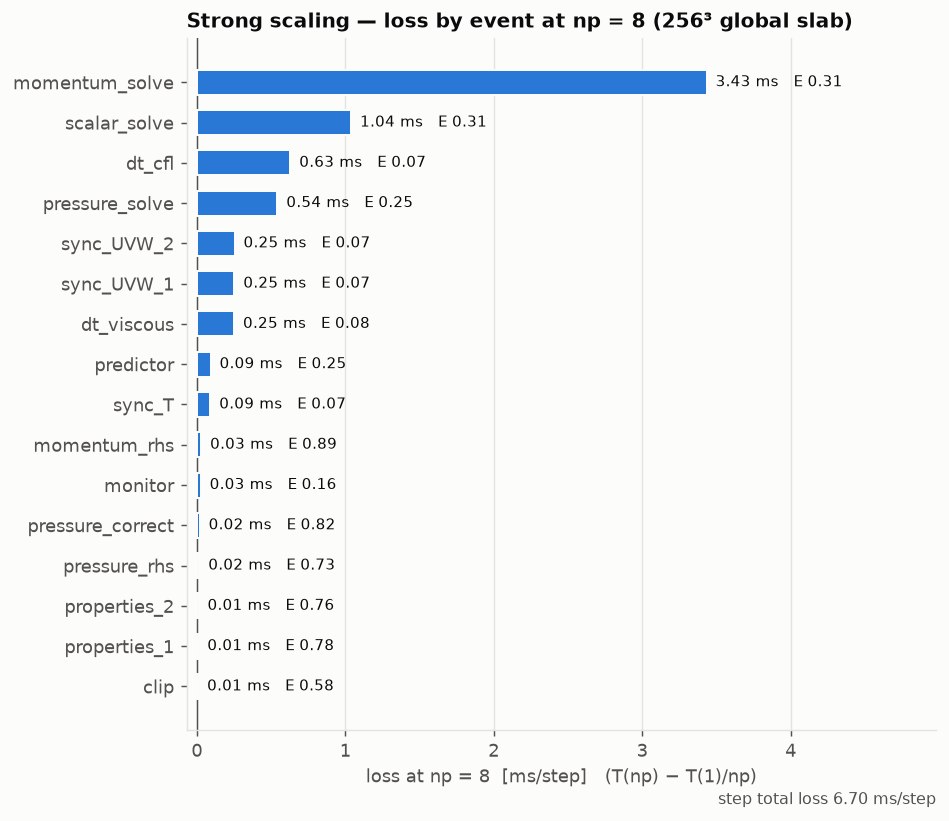

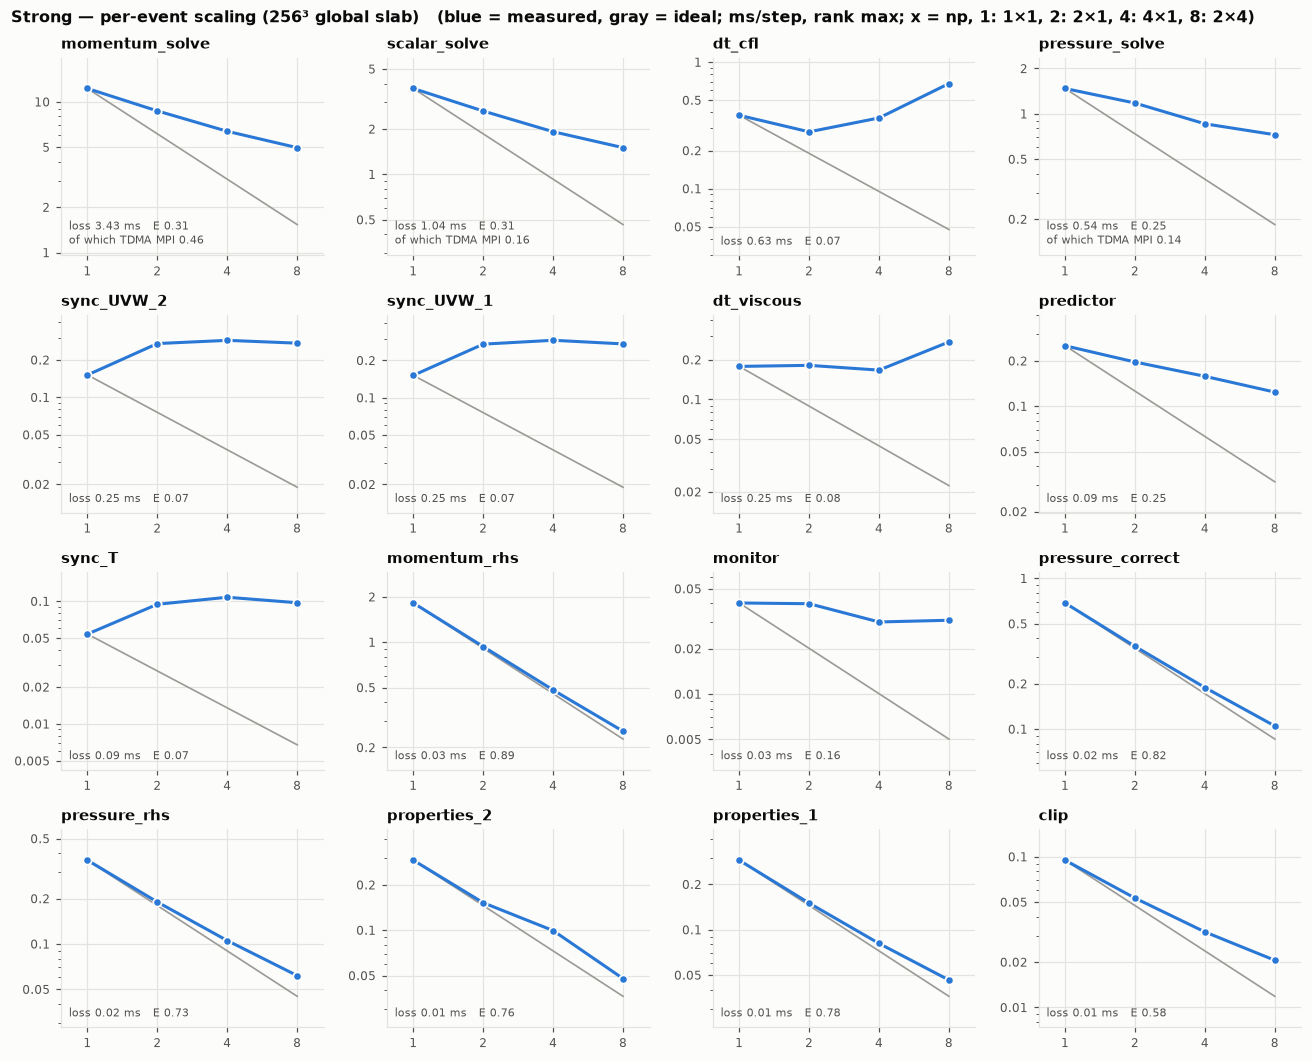

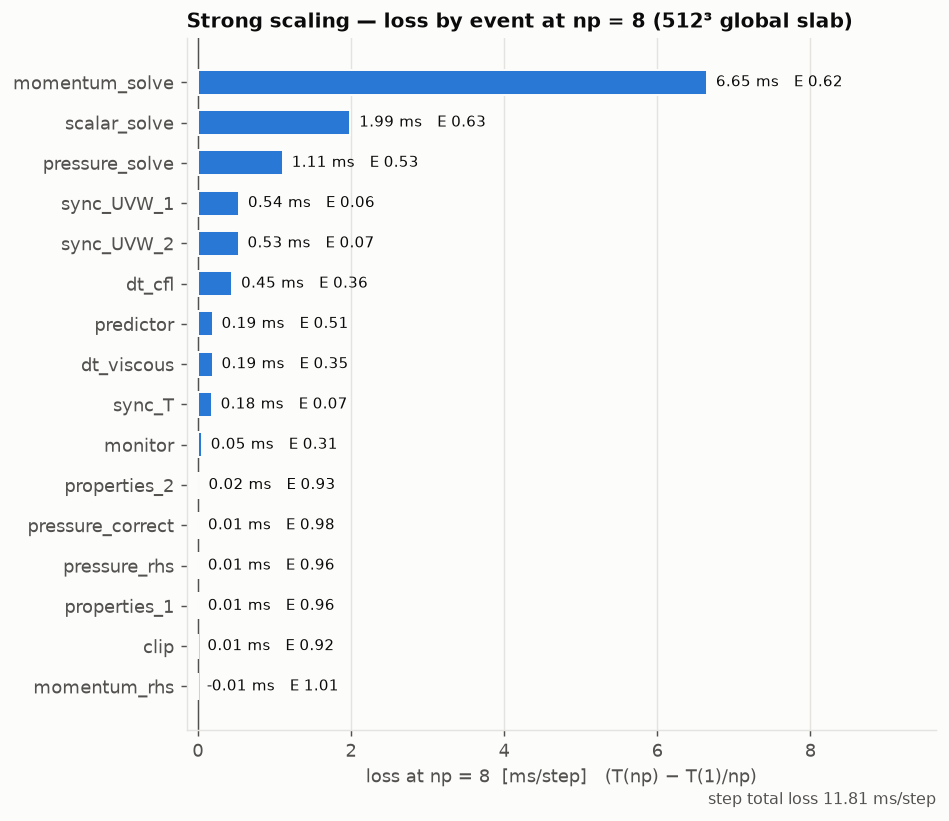

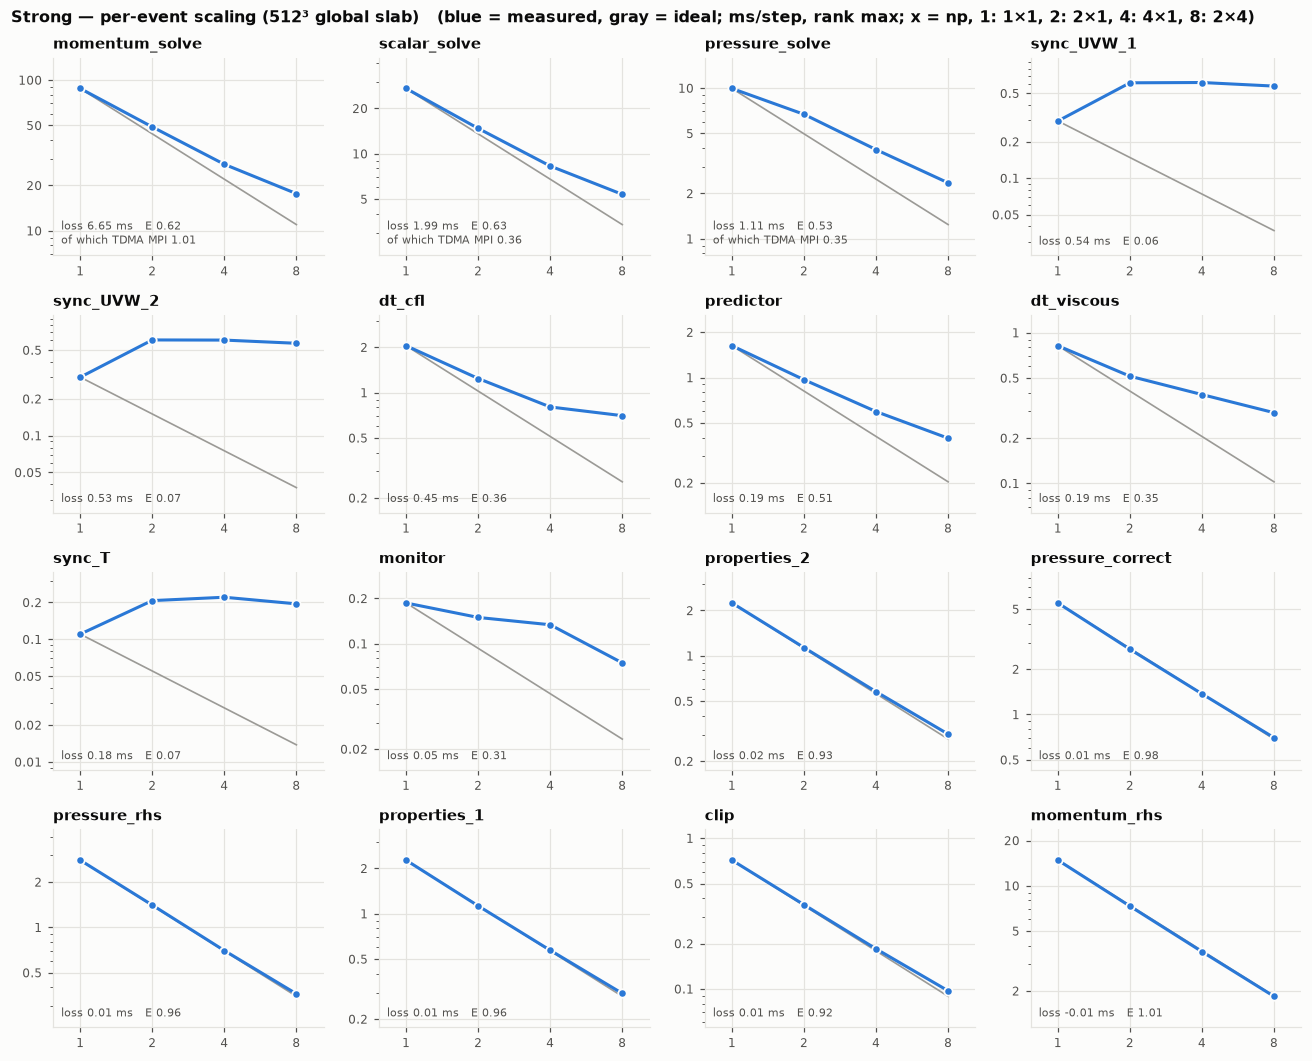

In [7]:
for s, d in data.items():
    if len(d) < 2:
        continue
    sp.loss_chart(d, MODE, title="Strong scaling — loss by event at np = %d (%s)" % (max(d), sp.label_of(s)),
                  fname="strong_loss_%s" % s)
    sp.event_grid(d, MODE, title="Strong — per-event scaling (%s)" % sp.label_of(s), fname="strong_events_%s" % s);

## 7. np 8 배치 비교 — 8 노드 × 1 vs 2 노드 × 4

2 노드 × 4 에서는 랭크 번호가 z 가 가장 빠르게 매겨져 (`MPI_Cart_create`, reorder 없음) pencil 의 z·y TDMA 통신자가
한 노드 안에 들어간다 (slab 은 z 통신자 8 랭크가 두 노드에 걸친다). 그림(1–5 절)은 8 노드 × 1 이다.

In [8]:
sp.placement_table(["results/pencil_internode"] + RESULTS["slab"][:1], list(data), 8)

study                      np  place   decomp    ms/step   TDMA MPI     halo runs
---------------------------------------------------------------------------------
strong_256_slab             8    2x4    1x1x8      9.477      0.763    0.642    2
strong_512_slab             8    2x4    1x1x8     31.645      1.715    1.338    2

place = 노드 x 노드당 랭크.  노드당 1 랭크면 모든 통신자가 노드 사이에 걸친다.
